# Task Singular Vectors (TSV) — Reimplementation
**Paper:** Gargiulo et al., *Task Singular Vectors: Reducing Task Interference in Model Merging*, CVPR 2025

**How to run:** Runtime → Change runtime type → **T4 GPU**, then run the cells top to bottom.
After a Colab restart, re-run Sections 0, 1, 2 and 3 before any experiment.

| Section | What it does |
|---|---|
| 0 | Setup (Drive, installs) |
| 1 | Load pretrained + fine-tuned checkpoints, build task vectors |
| 2 | Merging methods, written from scratch (Task Arithmetic, TSV-M, TSV-C, STI) |
| 3 | Model, datasets, evaluation |
| 4 | Main results (8 tasks) + comparison with the paper |
| 5 | Ablation study |
| 6 | Utilities (disk space, cache) |

---
## **0. Setup**
---

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p /content/drive/MyDrive/tsv_project/{checkpoints,data,results}
%cd /content/drive/MyDrive/tsv_project

# Official repo: only needed so torch.load can unpickle the classification-head objects
![ -d task_singular_vectors ] || git clone https://github.com/AntoAndGar/task_singular_vectors.git

!pip install -q open_clip_torch datasets hydra-core

/content/drive/MyDrive/tsv_project
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


---
## **1. Loading Checkpoints and Building Task Vectors**
---

In [3]:
!find /content/drive/MyDrive/tsv_project/checkpoints -name "*.pt" | sort | head -50

In [6]:
import sys, torch

ROOT = '/content/drive/MyDrive/tsv_project_1'
CKPT = f'{ROOT}/checkpoints/ViT-B-32'
sys.path.append(f'{ROOT}/task_singular_vectors')   # needed to unpickle the head objects

TASKS_8 = ['Cars', 'DTD', 'EuroSAT', 'GTSRB', 'MNIST', 'RESISC45', 'SUN397', 'SVHN']

def load_sd(path):
    # Load a checkpoint and return its weights as a state dict
    obj = torch.load(path, map_location='cpu', weights_only=False)
    return obj.state_dict() if hasattr(obj, 'state_dict') else obj

# Pretrained (zero-shot) weights = theta_pre
pre_sd = load_sd(f'{CKPT}/MNISTVal/nonlinear_zeroshot.pt')

# Task vectors: Delta_t = theta_ft - theta_pre, per layer
task_vectors = {}
for t in TASKS_8:
    ft_sd = load_sd(f'{CKPT}/{t}Val/nonlinear_finetuned.pt')
    task_vectors[t] = {k: ft_sd[k] - pre_sd[k] for k in pre_sd if pre_sd[k].dtype.is_floating_point}
    del ft_sd                                        # free RAM
    print(f'Loaded {t}')

n_matrix = sum(1 for k in pre_sd if pre_sd[k].ndim == 2)
print(f'\n{len(pre_sd)} parameters in total, {n_matrix} are 2D matrices (these get SVD)')

Loaded Cars
Loaded DTD
Loaded EuroSAT
Loaded GTSRB
Loaded MNIST
Loaded RESISC45
Loaded SUN397
Loaded SVHN

158 parameters in total, 53 are 2D matrices (these get SVD)


---
## **2. Merging Methods (implemented from scratch)**
---

**2.1 Task Arithmetic (baseline, Eq. 1)**

In [7]:
def task_arithmetic(pre_sd, task_vectors, alpha=0.3):
    # Eq. (1): merged = pretrained + alpha * sum of task vectors
    tv0 = next(iter(task_vectors.values()))
    merged = {}
    for k in pre_sd:
        if k in tv0:                                         # float layers only
            merged[k] = pre_sd[k] + alpha * sum(tv[k] for tv in task_vectors.values())
        else:
            merged[k] = pre_sd[k].clone()
    return merged

**2.2 TSV-Merge (Algorithm 1)**

`use_lowrank` / `use_orth` switch the two components on and off (ablation); `keep_frac` sets the rank k as a fraction of the layer's components (default 1/T).

In [8]:
def orthogonalize(X):
    # Procrustes / whitening (Prop. 4.1): X = P D Q^T  ->  P Q^T
    P, D, Qt = torch.linalg.svd(X, full_matrices=False)
    return P @ Qt

def tsv_merge(pre_sd, task_vectors, alpha=1.0, use_lowrank=True, use_orth=True,
              keep_frac=None, device='cuda'):
    tvs = list(task_vectors.values())
    T = len(tvs)
    frac = (1.0 / T if keep_frac is None else keep_frac) if use_lowrank else 1.0
    merged = {}
    for k in pre_sd:
        if k not in tvs[0]:                                  # non-float params
            merged[k] = pre_sd[k].clone(); continue
        if pre_sd[k].ndim != 2:                              # biases, LayerNorm: plain average
            merged[k] = pre_sd[k] + alpha * sum(tv[k] for tv in tvs) / T; continue

        # Lines 1-4: SVD of each task matrix, keep top-k
        Us, Ss, Vs = [], [], []
        for tv in tvs:
            U, S, Vh = torch.linalg.svd(tv[k].to(device).float(), full_matrices=False)
            keep = max(1, int(S.shape[0] * frac))
            Us.append(U[:, :keep]); Ss.append(S[:keep]); Vs.append(Vh[:keep, :].T)

        # Lines 5-8: concatenate  U = [U1|...|UT], Sigma = blockdiag, V = [V1|...|VT]
        U_all, S_all, V_all = torch.cat(Us, 1), torch.cat(Ss), torch.cat(Vs, 1)

        # Lines 9-12: decorrelate (remove task interference)
        if use_orth:
            U_all, V_all = orthogonalize(U_all), orthogonalize(V_all)

        # Lines 13-16: rebuild and add to pretrained
        merged[k] = pre_sd[k] + alpha * (U_all @ torch.diag(S_all) @ V_all.T).cpu()
    return merged

**2.3 TSV-Compress (per task, Eq. 7)**

In [9]:
def tsv_compress(pre_sd, task_vector, T, alpha=1.0, device='cuda'):
    # Keep only the top-k components of ONE task, k = r // T
    out = {}
    for k in pre_sd:
        if k not in task_vector:
            out[k] = pre_sd[k].clone()
        elif pre_sd[k].ndim != 2:
            out[k] = pre_sd[k] + alpha * task_vector[k]
        else:
            U, S, Vh = torch.linalg.svd(task_vector[k].to(device).float(), full_matrices=False)
            keep = max(1, S.shape[0] // T)
            low = U[:, :keep] @ torch.diag(S[:keep]) @ Vh[:keep, :]
            out[k] = pre_sd[k] + alpha * low.cpu()
    return out

**2.4 Singular Task Interference, STI (Eq. 6)**

In [10]:
def sti_value(U, S, V):
    # STI = || (U^T U - I) Sigma (V^T V - I) ||_1
    I = torch.eye(U.shape[1], device=U.device)
    return torch.abs((U.T @ U - I) @ torch.diag(S) @ (V.T @ V - I)).sum().item()

def sti_layer(layer, orth=False, keep_frac=None, device='cuda'):
    T = len(task_vectors)
    Us, Ss, Vs = [], [], []
    for tv in task_vectors.values():
        U, S, Vh = torch.linalg.svd(tv[layer].to(device).float(), full_matrices=False)
        keep = S.shape[0] // T if keep_frac is None else max(1, int(S.shape[0] * keep_frac))
        Us.append(U[:, :keep]); Ss.append(S[:keep]); Vs.append(Vh[:keep, :].T)
    U, S, V = torch.cat(Us, 1), torch.cat(Ss), torch.cat(Vs, 1)
    if orth:
        U, V = orthogonalize(U), orthogonalize(V)
    return sti_value(U, S, V)

**2.5 Quick checks (run before evaluating)**

In [11]:
merged_tsv = tsv_merge(pre_sd, task_vectors)

# 1. Shapes match the pretrained model
assert all(merged_tsv[k].shape == pre_sd[k].shape for k in pre_sd)
print('Shape check passed')

# 2. Proposition 4.1 numerically: whitening X (X^T X)^(-1/2) == Procrustes P Q^T
X = torch.randn(50, 20, dtype=torch.float64)
evals, evecs = torch.linalg.eigh(X.T @ X)
whiten = X @ evecs @ torch.diag(evals ** -0.5) @ evecs.T
print('Prop 4.1 error:', (whiten - orthogonalize(X)).norm().item())   # ~1e-14

# 3. Interference on one attention weight matrix, before and after TSV-M
layer = [k for k in pre_sd if 'attn.in_proj_weight' in k][0]
print(f'STI on {layer}: before {sti_layer(layer):.2f} | after {sti_layer(layer, orth=True):.6f}')

Shape check passed
Prop 4.1 error: 9.608816664276052e-15
STI on model.visual.transformer.resblocks.0.attn.in_proj_weight: before 2306.49 | after 0.000016


---
## **3. Model, Datasets and Evaluation**
---

**3.1 Settings** — change these here; every function below reads them at call time.

In [12]:
import torch.nn as nn, torch.nn.functional as F
import open_clip, pandas as pd

device = 'cuda'
TASKS_EVAL = TASKS_8      # datasets to evaluate on
MB = 20                   # batches per dataset: 20 for quick runs, None = full test set

**3.2 Image encoder**

The OpenAI CLIP weights use the QuickGELU activation, so the model is built as `ViT-B-32-quickgelu` (plain `ViT-B-32` gives a *QuickGELU mismatch* warning and slightly wrong accuracies).

In [13]:
class ImageEncoder(nn.Module):
    # CLIP ViT-B-32 image encoder. open_clip only builds the structure;
    # the weights are replaced by our checkpoints.
    def __init__(self):
        super().__init__()
        self.model, _, self.val_preprocess = open_clip.create_model_and_transforms(
            'ViT-B-32-quickgelu', pretrained='openai')
    def forward(self, x):
        return self.model.encode_image(x)

base_model = ImageEncoder()
preprocess = base_model.val_preprocess
print('checkpoint key example:', list(pre_sd.keys())[0])
print('model key example:     ', list(base_model.state_dict().keys())[0])

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

checkpoint key example: model.positional_embedding
model key example:      model.positional_embedding


**3.3 Load weights and classification heads**

In [14]:
def load_weights(model, sd):
    # Load checkpoint weights, fixing a 'model.' prefix mismatch if needed
    target_model = model
    if not any(k in model.state_dict() for k in sd):
        if all(k.startswith('model.') for k in sd):
            sd = {k[len('model.'):]: v for k, v in sd.items()}
            target_model = model.model
        else:
            sd = {'model.' + k: v for k, v in sd.items()}
    missing, _ = target_model.load_state_dict(sd, strict=False)
    vis_missing = [k for k in missing if 'visual' in k]
    assert not vis_missing, f'Missing image-encoder weights: {vis_missing[:5]}'
    return model

_heads = {}
def load_head(task):
    # Classification head for a task (handles both module and dict formats)
    if task not in _heads:
        obj = torch.load(f'{CKPT}/head_{task}Val.pt', map_location=device, weights_only=False)
        if isinstance(obj, nn.Module):
            _heads[task] = obj.to(device).eval()
        else:
            W, b = obj['weight'].to(device), obj.get('bias')
            b = b.to(device) if b is not None else 0
            _heads[task] = lambda f, W=W, b=b: F.normalize(f, dim=-1) @ W.T + b
    return _heads[task]

**3.4 Test-set loader (Hugging Face copies of the 8 benchmarks)**

Only the `test` split is downloaded for the large datasets, and data is cached on Colab's local disk (`/content/hf_cache`), not Drive.

In [15]:
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader

HF_IDS = {
    'Cars':     ('tanganke/stanford_cars', None),
    'DTD':      ('tanganke/dtd', None),
    'EuroSAT':  ('tanganke/eurosat', None),
    'GTSRB':    ('tanganke/gtsrb', None),
    'MNIST':    ('ylecun/mnist', None),
    'RESISC45': ('tanganke/resisc45', None),
    'SUN397':   ('tanganke/sun397', None),
    'SVHN':     ('ufldl-stanford/svhn', 'cropped_digits'),
}
SMALL = {'MNIST', 'SVHN'}          # small datasets: normal download is fine
HF_CACHE = '/content/hf_cache'

class HFImageDataset(Dataset):
    # Wraps a Hugging Face split: returns (preprocessed image, label)
    def __init__(self, hf_split):
        self.data = hf_split
    def __len__(self):
        return len(self.data)
    def __getitem__(self, i):
        item = self.data[i]
        return preprocess(item['image'].convert('RGB')), item['label']   # grayscale -> RGB

_cache = {}
def get_test_loader(task, batch_size=128):
    if task not in _cache:
        name, config = HF_IDS[task]
        if task in SMALL:
            _cache[task] = load_dataset(name, config, split='test', cache_dir=HF_CACHE)
        else:
            # Test split only; 'no_checks' stops it from also downloading train/corruption splits
            _cache[task] = load_dataset(name, data_files={'test': 'data/test-*.parquet'},
                                        split='test', cache_dir=HF_CACHE,
                                        verification_mode='no_checks')
    g = torch.Generator().manual_seed(0)       # same shuffled order every run (fair comparison)
    return DataLoader(HFImageDataset(_cache[task]), batch_size=batch_size,
                      shuffle=True, generator=g, num_workers=2)

**3.5 Evaluation helpers**

In [16]:
@torch.no_grad()
def evaluate(state_dict, task, max_batches='default', batch_size=128):
    # Accuracy (%) of the image encoder with the given weights on one task
    if max_batches == 'default':
        max_batches = MB
    encoder = load_weights(base_model, state_dict).to(device).eval()
    head = load_head(task)
    correct, total = 0, 0
    for i, (x, y) in enumerate(get_test_loader(task, batch_size)):
        if max_batches and i >= max_batches:
            break
        x, y = x.to(device), y.to(device)
        correct += (head(encoder(x)).argmax(dim=1) == y).sum().item()
        total += y.size(0)
    return 100 * correct / total

def finetuned_sd(task):
    # Individual fine-tuned model = pretrained + its task vector
    return {k: pre_sd[k] + task_vectors[task][k] if k in task_vectors[task] else pre_sd[k]
            for k in pre_sd}

# tasks=None / mb='default' -> use the CURRENT TASKS_EVAL / MB (read at call time)
def run_all(name, state_dict, tasks=None, max_batches='default'):
    tasks = TASKS_EVAL if tasks is None else tasks
    row = {'method': name}
    for t in tasks:
        row[t] = evaluate(state_dict, t, max_batches)
        print(f'{name:>10} | {t:>8}: {row[t]:.2f}')
    row['avg'] = sum(row[t] for t in tasks) / len(tasks)
    return row

def avg_acc(sd, tasks=None, mb='default'):
    tasks = TASKS_EVAL if tasks is None else tasks
    accs = {t: evaluate(sd, t, mb) for t in tasks}
    accs['avg'] = sum(accs.values()) / len(tasks)
    return accs

**3.6 Sanity check** — fine-tuned accuracy should be high on every task (a near-random value means a label-order mismatch). The first run downloads the datasets; SUN397 (~7 GB) is the slowest.

In [17]:
for t in TASKS_EVAL:
    print(f'{t:>8} | zero-shot: {evaluate(pre_sd, t, 10):5.1f}'
          f' | fine-tuned: {evaluate(finetuned_sd(t), t, 10):5.1f}')

README.md:   0%|          | 0.00/11.0k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  513MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  474MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

cropped_digits/extra-00001-of-00002.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/73257 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/26032 [00:00<?, ? examples/s]

Generating extra split:   0%|          | 0/531131 [00:00<?, ? examples/s]

    SVHN | zero-shot:  32.7 | fine-tuned:  97.8


---
## **4. Main Results (8 tasks) + Comparison with the Paper**
---
Run with `MB = 20` first; set `MB = None` in 3.1 for the final report numbers (~30–60 min). Each finished method is saved to CSV immediately, so a disconnect doesn't lose results.

In [18]:
tag = 'full' if MB is None else f'mb{MB}'
out_csv = f'{ROOT}/results/main_8tasks_{tag}.csv'
final = []

def save_row(row):
    final.append(row)
    pd.DataFrame(final).to_csv(out_csv, index=False)

save_row(run_all('Zero-shot', pre_sd))
save_row(run_all('TaskArith', task_arithmetic(pre_sd, task_vectors, 0.3)))
save_row(run_all('TSV-M',     tsv_merge(pre_sd, task_vectors)))

# Fine-tuned and TSV-C use a separate model per task
ft_row, tsvc_row = {'method': 'Finetuned'}, {'method': 'TSV-C'}
for t in TASKS_EVAL:
    ft_row[t]   = evaluate(finetuned_sd(t), t)
    tsvc_row[t] = evaluate(tsv_compress(pre_sd, task_vectors[t], T=len(task_vectors)), t)
    print(f'{t:>8}: finetuned {ft_row[t]:.2f} | TSV-C {tsvc_row[t]:.2f}')
for r in (ft_row, tsvc_row):
    r['avg'] = sum(r[t] for t in TASKS_EVAL) / len(TASKS_EVAL)
    save_row(r)

 Zero-shot |     Cars: 60.08
 Zero-shot |      DTD: 44.41
 Zero-shot |  EuroSAT: 45.20
 Zero-shot |    GTSRB: 32.42
 Zero-shot |    MNIST: 47.46
 Zero-shot | RESISC45: 60.74
 Zero-shot |   SUN397: 61.56
 Zero-shot |     SVHN: 30.98
 TaskArith |     Cars: 55.23
 TaskArith |      DTD: 56.65
 TaskArith |  EuroSAT: 75.78
 TaskArith |    GTSRB: 70.23
 TaskArith |    MNIST: 97.30
 TaskArith | RESISC45: 67.66
 TaskArith |   SUN397: 53.83
 TaskArith |     SVHN: 78.12
     TSV-M |     Cars: 70.78
     TSV-M |      DTD: 84.84
     TSV-M |  EuroSAT: 94.45
     TSV-M |    GTSRB: 91.88
     TSV-M |    MNIST: 99.38
     TSV-M | RESISC45: 86.64
     TSV-M |   SUN397: 65.78
     TSV-M |     SVHN: 91.21
    Cars: finetuned 78.55 | TSV-C 77.15
     DTD: finetuned 97.66 | TSV-C 97.39
 EuroSAT: finetuned 99.80 | TSV-C 99.80
   GTSRB: finetuned 99.30 | TSV-C 99.10
   MNIST: finetuned 99.80 | TSV-C 99.80
RESISC45: finetuned 95.70 | TSV-C 95.59
  SUN397: finetuned 74.38 | TSV-C 73.44
    SVHN: finetuned 97.8

In [19]:
df = pd.DataFrame(final).set_index('method')
df['normalized'] = 100 * (df[TASKS_EVAL] / df.loc['Finetuned', TASKS_EVAL]).mean(axis=1)
df['paper_avg'] = pd.Series({'Zero-shot': 48.26, 'TaskArith': 70.79, 'TSV-M': 85.86,
                             'Finetuned': 92.83, 'TSV-C': 92.62})     # Tables 2-3, ViT-B-32
df.to_csv(out_csv)
df.round(2)

,Cars,DTD,EuroSAT,GTSRB,MNIST,RESISC45,SUN397,SVHN,avg,normalized,paper_avg
method,,,,,,,,,,,
Zero-shot,60.08,44.41,45.20,32.42,47.46,60.74,61.56,30.98,47.86,53.17,48.26
TaskArith,55.23,56.65,75.78,70.23,97.30,67.66,53.83,78.12,69.35,74.42,70.79
TSV-M,70.78,84.84,94.45,91.88,99.38,86.64,65.78,91.21,85.62,91.99,85.86
Finetuned,78.55,97.66,99.80,99.30,99.80,95.70,74.38,97.85,92.88,100.00,92.83
TSV-C,77.15,97.39,99.80,99.10,99.80,95.59,73.44,97.85,92.52,99.54,92.62


---
## **5. Ablation Study**
---
Uses `MB = 20` batches per dataset (enough to see trends).

**5.1 Component ablation (Table 4)** — both α = 1 and the fairer version where the rows without orthogonalization use tuned α = 0.3 (as in the paper's Table 4).

In [20]:
abl = []
for lowrank, orth, a in [(False, False, 1.0), (True, False, 1.0),
                         (False, False, 0.3), (True, False, 0.3),
                         (False, True, 1.0),  (True, True, 1.0)]:
    r = avg_acc(tsv_merge(pre_sd, task_vectors, alpha=a, use_lowrank=lowrank, use_orth=orth), mb=20)
    r.update({'low_rank': lowrank, 'interf_reduction': orth, 'alpha': a})
    abl.append(r)
    print(f'low-rank={lowrank!s:5} | orth={orth!s:5} | alpha={a} | avg={r["avg"]:.2f}')

df_abl = pd.DataFrame(abl)
df_abl.to_csv(f'{ROOT}/results/ablation_components.csv', index=False)
df_abl.round(2)

low-rank=False | orth=False | alpha=1.0 | avg=25.82
low-rank=True  | orth=False | alpha=1.0 | avg=25.31
low-rank=False | orth=False | alpha=0.3 | avg=70.69
low-rank=True  | orth=False | alpha=0.3 | avg=69.86
low-rank=False | orth=True  | alpha=1.0 | avg=71.68
low-rank=True  | orth=True  | alpha=1.0 | avg=85.62


,Cars,DTD,EuroSAT,GTSRB,MNIST,RESISC45,SUN397,SVHN,avg,low_rank,interf_reduction,alpha
0,0.74,11.22,30.35,18.98,89.65,6.76,0.74,48.12,25.82,False,False,1.0
1,0.82,11.86,29.80,18.98,88.75,6.91,0.70,44.65,25.31,True,False,1.0
2,56.95,58.24,77.85,72.50,96.60,69.69,56.21,77.50,70.69,False,False,0.3
3,56.84,56.22,77.30,70.78,96.41,69.41,55.23,76.72,69.86,True,False,0.3
4,65.47,61.01,78.83,64.61,92.42,76.45,65.82,68.87,71.68,False,True,1.0
5,70.78,84.84,94.45,91.88,99.38,86.64,65.78,91.21,85.62,True,True,1.0


**5.2 Effect of rank k** (fraction of singular components kept per task; 1/T = 0.125 is the paper default)

In [21]:
fracs = [0.01, 0.03, 0.05, 0.125, 0.2, 0.3]
rank_res = []
for f in fracs:
    r = avg_acc(tsv_merge(pre_sd, task_vectors, keep_frac=f), mb=20)
    r['keep_frac'] = f
    rank_res.append(r)
    print(f'keep {f:.3f} -> avg {r["avg"]:.2f}')

df_rank = pd.DataFrame(rank_res)
df_rank.to_csv(f'{ROOT}/results/ablation_rank.csv', index=False)

keep 0.010 -> avg 75.56
keep 0.030 -> avg 81.97
keep 0.050 -> avg 84.29
keep 0.125 -> avg 85.62
keep 0.200 -> avg 84.72
keep 0.300 -> avg 82.67


**5.3 Effect of scaling factor α** (TSV-M vs Task Arithmetic)

In [22]:
alphas = [0.2, 0.3, 0.5, 0.8, 1.0, 1.2, 1.5]
alpha_res = []
for a in alphas:
    alpha_res.append({'alpha': a,
                      'TSV-M':     avg_acc(tsv_merge(pre_sd, task_vectors, alpha=a), mb=20)['avg'],
                      'TaskArith': avg_acc(task_arithmetic(pre_sd, task_vectors, a), mb=20)['avg']})
    print({k: round(v, 2) for k, v in alpha_res[-1].items()})

df_alpha = pd.DataFrame(alpha_res)
df_alpha.to_csv(f'{ROOT}/results/ablation_alpha.csv', index=False)

{'alpha': 0.2, 'TSV-M': 63.28, 'TaskArith': 70.52}
{'alpha': 0.3, 'TSV-M': 69.78, 'TaskArith': 69.35}
{'alpha': 0.5, 'TSV-M': 78.94, 'TaskArith': 50.84}
{'alpha': 0.8, 'TSV-M': 84.88, 'TaskArith': 29.22}
{'alpha': 1.0, 'TSV-M': 85.62, 'TaskArith': 20.53}
{'alpha': 1.2, 'TSV-M': 84.89, 'TaskArith': 13.17}
{'alpha': 1.5, 'TSV-M': 80.66, 'TaskArith': 7.15}


**5.4 Interference (STI) per layer, before and after orthogonalization**

In [23]:
matrix_layers = [k for k in pre_sd if pre_sd[k].ndim == 2 and k in task_vectors['MNIST']]
df_sti = pd.DataFrame([{'layer': L, 'before': sti_layer(L, orth=False),
                        'after': sti_layer(L, orth=True)} for L in matrix_layers])
df_sti.to_csv(f'{ROOT}/results/sti_layers.csv', index=False)
print('Total STI before:', df_sti.before.sum(), '| after:', df_sti.after.sum())

Total STI before: 42272.651027202606 | after: 0.0005905013559116962


**5.5 Plots for the report**

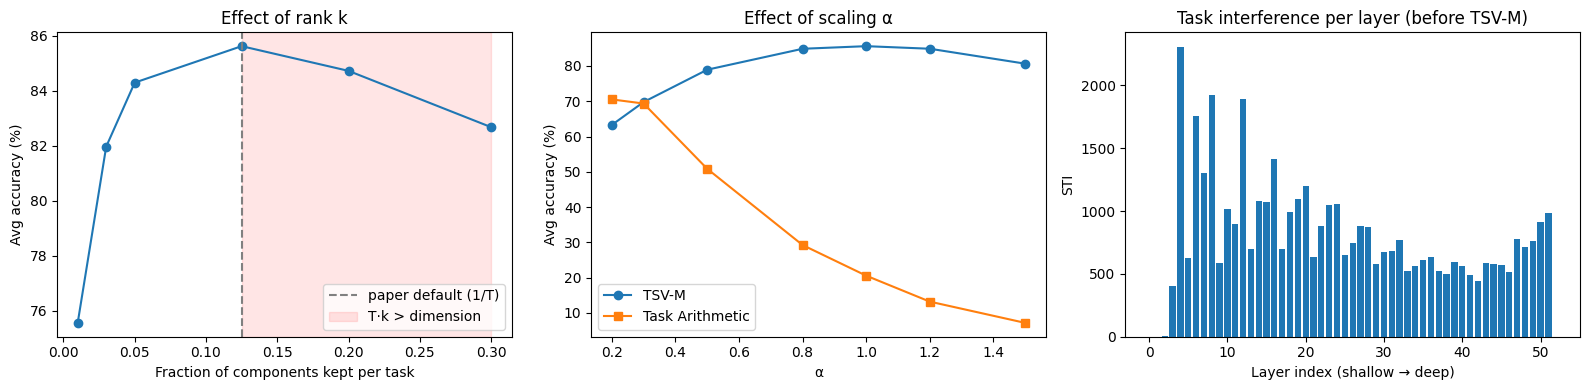

In [24]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(df_rank.keep_frac, df_rank.avg, 'o-')
ax[0].axvline(1/8, ls='--', c='gray', label='paper default (1/T)')
ax[0].axvspan(1/8, max(fracs), alpha=0.1, color='red', label='T·k > dimension')
ax[0].set(xlabel='Fraction of components kept per task', ylabel='Avg accuracy (%)',
          title='Effect of rank k'); ax[0].legend()

ax[1].plot(df_alpha.alpha, df_alpha['TSV-M'], 'o-', label='TSV-M')
ax[1].plot(df_alpha.alpha, df_alpha['TaskArith'], 's-', label='Task Arithmetic')
ax[1].set(xlabel='α', ylabel='Avg accuracy (%)', title='Effect of scaling α'); ax[1].legend()

ax[2].bar(range(len(df_sti)), df_sti.before)
ax[2].set(xlabel='Layer index (shallow → deep)', ylabel='STI',
          title='Task interference per layer (before TSV-M)')

plt.tight_layout()
plt.savefig(f'{ROOT}/results/ablation_plots.png', dpi=200)
plt.show()

---
## **6. Utilities**
---

In [25]:
!df -h /content                       # free space on the Colab disk
!du -sh /content/hf_cache/* 2>/dev/null

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   66G   48G  58% /
0	/content/hf_cache/_content_hf_cache_tanganke___dtd_default-c69100db30ae6eda_0.0.0_d2afa97d9f335b1a6b3b09c637aef667f98f966e.lock
0	/content/hf_cache/_content_hf_cache_tanganke___eurosat_default-4671b4467ebf9039_0.0.0_43750fc422c7fbd4289e2df3f7473617a5937acc.lock
0	/content/hf_cache/_content_hf_cache_tanganke___gtsrb_default-a8da005426ef21d4_0.0.0_ea889fff70dda7b09e94a4b207dded438deca549.lock
0	/content/hf_cache/_content_hf_cache_tanganke___resisc45_default-9fffdccb44b39c1c_0.0.0_5c484982a196dcb501b8e79c6cf4680dc6f2ccdf.lock
0	/content/hf_cache/_content_hf_cache_tanganke___stanford_cars_default-49d91cb127009a14_0.0.0_9abf6cf7d6dfa7b95152a0d6e791ea9435b47a40.lock
0	/content/hf_cache/_content_hf_cache_tanganke___sun397_default-09ada9737bbc93d9_0.0.0_9c4afd6174afa3974f209a0ef099dbbe244dfd27.lock
0	/content/hf_cache/_content_hf_cache_ufldl-stanford___svhn_cropped_digits_0.0.0_f9e1717d73324ebbc1ece84267

In [ ]:
# Free space: raw downloaded files are no longer needed once a dataset
# has been loaded ('Generating test split' finished). Uncomment to run.
# !rm -rf /content/hf_cache/downloads
# Delete ALL cached datasets (they re-download when needed):
# !rm -rf /content/hf_cache